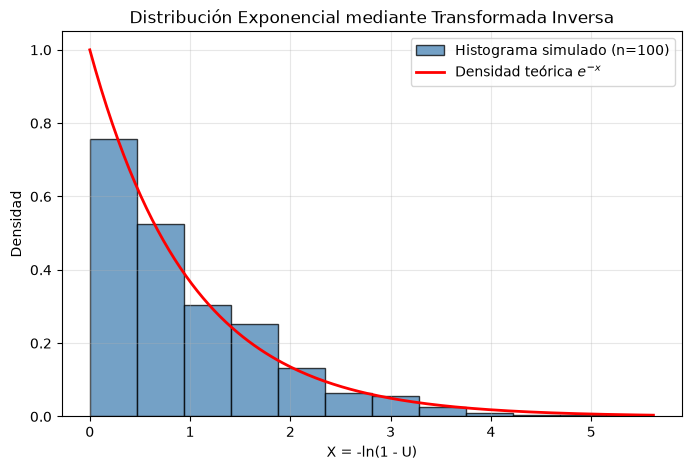

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Generar 100 variables aleatorias uniformes U ~ U(0, 1)
n = 500
U = np.random.uniform(0, 1, n)

# 2. Evaluar en X = -ln(1 - U) para obtener variables exponenciales (lambda = 1)
# Para una tasa lambda distinta de 1, usa: X = -np.log(1 - U) / lambd
X = -np.log(1 - U)

# 3. Generar el histograma
plt.figure(figsize=(8, 5))
plt.hist(
    X,
    bins=12,
    density=True,
    alpha=0.75,
    color="steelblue",
    edgecolor="black",
    label="Histograma simulado (n=100)",
)

# Curva de densidad teórica f(x) = e^(-x)
x_teorico = np.linspace(0, max(X), 200)
plt.plot(
    x_teorico,
    np.exp(-x_teorico),
    "r-",
    linewidth=2,
    label="Densidad teórica $e^{-x}$",
)

plt.title("Distribución Exponencial mediante Transformada Inversa")
plt.xlabel("X = -ln(1 - U)")
plt.ylabel("Densidad")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [7]:
import numpy as np
from scipy import stats

X = -np.log(1 - np.random.uniform(0, 1, 100))
D, p = stats.kstest(X, "expon")  # Evalúa Exp(lambda=1) por defecto

print(
    f"D = {D:.4f}, p = {p:.4f} ->"
    f" {'Sigue la exponencial' if p > 0.05 else 'No sigue la exponencial'}"
)

D = 0.0575, p = 0.8762 -> Sigue la exponencial


Estadístico K-S (D): 0.0393
Valor p:             0.4125
Decisión (alpha=0.05): No se rechaza H0. Los datos se ajustan a Exp(lambda=1.0).


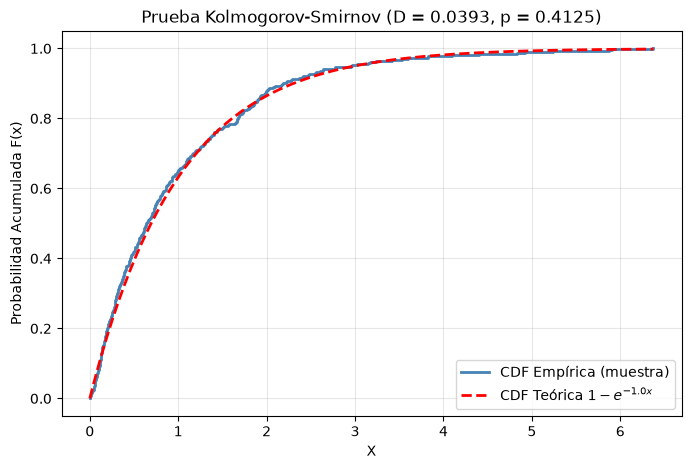

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 1. Generar las 100 variables exponenciales (lambda = 1)
n = 500
U = np.random.uniform(0, 1, n)
X = -np.log(1 - U)

# 2. Prueba de bondad de ajuste de Kolmogorov-Smirnov
# En scipy, para Exponencial(lambda), loc=0 y scale=1/lambda
lambd = 1.0
estadistico_D, p_valor = stats.kstest(X, "expon", args=(0, 1 / lambd))

# 3. Resultados y decisión estadística (nivel de significancia alpha = 0.05)
alpha = 0.05
print(f"Estadístico K-S (D): {estadistico_D:.4f}")
print(f"Valor p:             {p_valor:.4f}")

if p_valor > alpha:
    print(
        f"Decisión (alpha={alpha}): No se rechaza H0. Los datos se ajustan a"
        f" Exp(lambda={lambd})."
    )
else:
    print(
        f"Decisión (alpha={alpha}): Se rechaza H0. Los datos no se ajustan a"
        f" Exp(lambda={lambd})."
    )

# 4. Gráfica comparativa: CDF Empírica vs. CDF Teórica
x_ord = np.sort(X)
cdf_empirica = np.arange(1, n + 1) / n
x_teorico = np.linspace(0, max(X), 200)
cdf_teorica = 1 - np.exp(-lambd * x_teorico)

plt.figure(figsize=(8, 5))
plt.step(
    x_ord,
    cdf_empirica,
    where="post",
    color="steelblue",
    linewidth=2,
    label="CDF Empírica (muestra)",
)
plt.plot(
    x_teorico,
    cdf_teorica,
    "r--",
    linewidth=2,
    label=f"CDF Teórica $1 - e^{{-{lambd}x}}$",
)

plt.title(f"Prueba Kolmogorov-Smirnov (D = {estadistico_D:.4f}, p = {p_valor:.4f})")
plt.xlabel("X")
plt.ylabel("Probabilidad Acumulada F(x)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()